In [4]:
# run in your virtual environment to install missing modules:
# pip install -r requirements.txt

# setup cell
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import yfinance as yf
from scipy import stats
from scipy.stats import kruskal, levene, spearmanr
import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
sns.set_palette("muted")


In [5]:
# Zeichenzähler
from pathlib import Path
import nbformat
import re

notebook_path = Path("report_notebook.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = nbformat.read(f, as_version=4)

text = "".join(
    cell.source
    for cell in nb.cells
    if cell.cell_type == "markdown"
)

ZoL = len(re.sub(r"\s+", "", text))

print("Zeichen ohne Leerzeichen:", ZoL)

Zeichen ohne Leerzeichen: 23867


{{< pagebreak >}}

# 1 Einleitung
## 1.1 Motivation
Kaum ein Konzept der Finanzmärkte ist so intuitiv und gleichzeitig so zentral wie die Idee, nicht alles „auf eine Karte“ zu setzen. Diversifikation gilt als eines der wichtigsten Instrumente zur Begrenzung von Risiken an den Kapitalmärkten. Ihre Wirksamkeit hängt jedoch entscheidend davon ab, wie sich die Renditen der betrachteten Wertpapiere zueinander verhalten. Diese Beziehungen werden in der Praxis meist durch Korrelationen beschrieben, die auf historischen Daten geschätzt werden und anschließend als Grundlage für Portfolio- und Risikomodelle dienen. Implizit wird dadurch jedoch angenommen, dass die beobachtete Korrelationsstruktur hinreichend stabil ist, um auch zukünftige Marktphasen angemessen abzubilden.

Diese Annahme ist empirisch jedoch umstritten. Zahlreiche Untersuchungen deuten darauf hin, dass sich Korrelationsstrukturen in Phasen hoher Marktunsicherheit verändern und die Abhängigkeiten zwischen Aktienrenditen zunehmen, siehe z.B. @longin2001. Dies würde bedeuten, dass Diversifikationseffekte gerade in den krisengeprägten Zeiten versagen, in denen man auf diese angewiesen ist. 

## 1.2 Forschungsfrage und Zielsetzung
In Anbetracht dieser Zusammenhänge ergibt sich nicht nur eine finanzwirtschaftliche, sondern vor allem eine statistische Fragestellung: Sind Korrelationen zeitlich stabil, oder hängen sie systematisch vom jeweiligen Marktregime ab? Falls Letzteres zutrifft, wären Schätzungen aus ruhigen Marktphasen nur eingeschränkt auf Krisen übertragbar. Die Arbeit untersucht daher, ob sich die Korrelationsstruktur zwischen ausgewählten Aktien unter Marktstress signifikant von der einer ruhigen Marktphase unterscheidet und insbesondere, ob die Korrelation im Marktstress zunimmt. Daraus wird folgende gerichtete Forschungshypothese abgeleitet: 

$$ H_1: \rho_{stress} > \rho_{normal} $$
Die durchschnittliche paarweise Korrelation ist im Stressregime höher als im Normalregime. Die zugehörige Nullhypothese lautet entsprechend $$ H_0: \rho_{stress} \le \rho_{normal} $$


{{< pagebreak >}}

# 2 Datensatz und Literaturübersicht
## 2.1 Finanztheoretischer Hintergrund
Die moderne Portfoliotheorie geht auf @markowitz1952 zurück, welcher zeigt, dass das Risiko eines Portfolios nicht durch die gewichtete Summe der Einzelrisiken bestimmt wird, sondern durch die paarweisen Korrelationen zwischen den enthaltenen Einzelwerten. Die Portfoliovarianz ergibt sich demnach formal als:

$$\sigma_p^2 = \sum_i \sum_j w_i w_j \sigma_i \sigma_j \rho_{ij}
$$

wobei $w_i$ das Gewicht der Aktie $i$, $\sigma_i$ die Standardabweichung der Rendite von Aktie $i$ und $\rho_{ij}$ die Korrelation zwischen Aktie $i$ und Aktie $j$ bezeichnet.​

Je niedriger die paarweisen Korrelationen, desto stärker der Diversifikationseffekt. Das Ziel der Diversifikation, die Reduktion des Portfoliorisikos durch Kombination nicht perfekt korrelierter Anlagen, setzt jedoch voraus, dass die Korrelationszusammenhänge zeitlich stabil sind.

Diese Annahme der Stabilität wird jedoch durch die empirischen Eigenschaften von Finanzzeitreihen in Frage gestellt. @cont2001 dokumentiert eine Reihe statistischer Regelmäßigkeiten, die systematisch in Renditezeitreihen auftreten, als Stylized Facts. Dazu gehören insbesondere schwere Tails (excess kurtosis > 0), ausgeprägte Volatilitätsbündelung (zeitliche Häufung von Perioden hoher bzw. niedriger Volatilität) sowie Asymmetrien in der Verteilung. Diese Eigenschaften stellen parametrische Tests in Frage und legen nahe, dass Korrelationsschätzungen in Hochvolatilitätsphasen nicht mit ruhigen Marktphasen vergleichbar sind.

Für die Frage der Korrelationsdynamik in Zeiten von Krisen sind zwei Studien zentral. @longin2001 zeigen, dass internationale Aktienmarktkorrelationen in Bear Markets signifikant höher sind als in Bull Markets, und zwar asymmetrisch. Dieses Ergebnis stützt die Hypothese, dass Diversifikation genau dann an Wirksamkeit verliert, wenn sie am dringendsten benötigt wird. @forbes2002 ergänzen diese Ergebnisse um einen wichtigen methodischen Einwand. Ein beobachteter Anstieg des Korrelationskoeffizienten nach Pearson in Krisenzeiten kann zu einem wesentlichen Teil durch die erhöhte Volatilität bei Marktstress erklärt werden. Unterschiedliche Varianzen zwischen den Marktphasen können die Pearson-Korrelation beeinflussen. Ein beobachteter Anstieg im Stressregime deutet daher nicht ausschließlich auf eine veränderte Abhängigkeitsstruktur hin, sondern kann teilweise durch den Volatility-Bias bedingt sein. Ein Bias-korrigierter Schätzer wird in dieser Arbeit nicht geliefert.

## 2.2 Operationalisierung
Für die empirische Untersuchung muss das zentrale Konzept des Marktstress in messbare Größen überführt werden.

Konzeptionell wird Marktstress in dieser Arbeit als eine Marktphase mit erhöhter Unsicherheit, ausgeprägter Risikoaversion der Marktteilnehmer und überdurchschnittlichen Kursschwankungen verstanden. Abzugrenzen ist dieses Konzept vom Normalregime, in dem Preisfindung unter stabilen Erwartungen und niedriger impliziter Unsicherheit stattfindet.

Operational wird Marktstress über den CBOE Volatility Index (VIX) gemessen. Der VIX misst die vom Markt implizit erwartete annualisierte Volatilität des S&P 500 über einen Horizont von 30 Tagen, abgeleitet aus den Preisen gehandelter Indexoptionen [@cboe_vix]. Er gilt in der Literatur als etabliertes Maß für Marktangst und Unsicherheit, vgl. @whaley2000, und ist auf täglicher Basis verfügbar. Die inhaltliche Validität ist gegeben, da der VIX die erwartete Volatilität als zentralen Aspekt der Unsicherheit am Aktienmarkt abbildet. Eine konkrete Einteilung der Handelstage in Regime auf Basis des VIX sowie die Begründung der gewählten Schwellenwerte werden in Kapitel 3.1 dargelegt.


## 2.3 Datengrundlage und Stichprobenziehung
Die Analyse basiert auf täglichen Schlusskursen des S&P 500, welcher als Index die 500 führenden börsennotierten US-amerikanischen Unternehmen umfasst [@sp500]. Die Daten werden über die Yahoo Finance API [Datenquelle @yfinance] für den Zeitraum vom 1. Januar 2018 bis zum 1. Januar 2026 bezogen. Wie zuvor bereits erläutert, wird als Stressindikator der tägliche Schlusskurs des VIX verwendet. Der Beobachtungszeitraum deckt sowohl ruhige Phasen (2019, 2021) als auch ausgeprägte Stressphasen (COVID-19-Krise, Zinsanstieg 2022) ab, was die Variation der Regime-Variable sicherstellt. Da die Kursdaten durch Yahoo Finance automatisch abgerufen werden, ist eine hohe Datengenauigkeit gegeben.

Die Grundgesamtheit umfasst alle aktuellen S&P 500-Mitglieder der fünf betrachteten Sektoren, für die sowohl am ersten als auch am letzten Handelstag des Beobachtungszeitraums ein Schlusskurs vorliegt. Dies stellt sicher, dass die Zeitreihen den gesamten Zeitraum abdecken, führt jedoch zu einem Survivorship Bias, da ausgeschiedene (tendenziell schwächere) Unternehmen fehlen.

Die Stichprobenziehung erfolgt als stratifizierte Zufallsstichprobe nach GICS-Sektor. Innerhalb jeder der fünf Gruppen Technology, Financials, Healthcare, Energy und Consumer werden sechs Unternehmen zufällig aus dem jeweiligen Pool gezogen (Gesamtstichprobe n = 30). Die Stratifizierung stellt sicher, dass alle ausgewählten Sektoren systematisch in der Stichprobe vertreten sind. Dadurch wird eine breitere und ausgewogenere Grundlage für die inferenzstatistische Ableitung und die Übertragbarkeit der Ergebnisse geschaffen. Die jeweiligen Sektoren wurden gewählt, um eine breite Marktabdeckung zu gewährleisten, und da unterschiedliche Krisenexpositionen erwartet werden können. Die Ergebnisse sind auf US-Großunternehmen im S&P 500 begrenzt und nicht auf andere Märkte übertragbar.

 Die Stichprobenziehung erfolgt bei festem Zufallsseed, was die Reproduzierbarkeit gewährleistet. Die Zusammensetzung des S&P 500 wird anhand von @sp500 referenziert. Die constituents.csv basiert aus technischen Gründen auf der von Wikipedia bereitgestellten aktuellen Liste der Konstituenten [@wiki-sp500], da diese per Python jederzeit automatisiert aktualisiert und reproduzierbar bezogen werden kann. Dies ist über die Dokumentation von S&P Global nicht möglich.

In [6]:
#| output: false
%run sampling.py

Universum: 310 Aktien
{'Consumer': 81, 'Financials': 76, 'Technology': 73, 'Healthcare': 59, 'Energy': 21}

Erster Handelstag: 2018-01-02
Letzter Handelstag: 2025-12-31

Survivors: 296 Aktien (Kurs am 2018-01-02 und 2025-12-31 vorhanden)
{'Technology': 68, 'Financials': 74, 'Healthcare': 56, 'Energy': 20, 'Consumer': 78}

raw_prices: 2011 Tage × 31 Spalten
Enthält: 30 Aktien + VIX


Die Übersicht der Sample-Unternehmen und Aktienticker nach den jeweiligen Sektoren ist in Anhang [A.1](#tabelle-a1-vollständige-stichprobenübersicht) dargestellt. Eine genauere Betrachtung zu den fehlenden Handelstagen und der Rolle von Nichtbörsentagen folgt im Kapitel 3.1. 

{{< pagebreak >}}

# 3 Empirische Analyse
## 3.1 Datenaufbereitung und Regimedefinition
Finanzzeitreihen sind in der empirischen Kapitalmarktforschung typischerweise durch eine hohe, aber teilweise nicht vollständige Datenverfügbarkeit gekennzeichnet. Die Rohdaten werden auf fehlende Werte geprüft, da diese bei multivariaten Korrelationsanalysen zu Verzerrungen führen können.

In [7]:
missing_pct = raw_prices[all_tickers].isnull().mean() * 100
flagged = missing_pct[missing_pct > 1]

# Output
print("Aktien mit > 1 % fehlenden Werten:", flagged if len(flagged) else "Keine")

Aktien mit > 1 % fehlenden Werten: Keine


Die explorative Analyse ergibt keine fehlenden Werte im klassischen Sinne. Börsenfeiertage, zu denen kein Handel stattfindet, werden von Yahoo Finance strukturell nicht als fehlende Einträge erfasst, sondern vollständig ausgelassen. Das Fehlen ist durch den Börsenkalender determiniert und tritt unabhängig vom tatsächlichen Kurswert der jeweiligen Aktie auf. Dies ist für die Analyse unproblematisch.

Methodisch durchaus relevant ist jedoch die Zeitreihensynchronisierung. Da verschiedene Aktien geringfügig unterschiedliche Handelskalender aufweisen können, wird der gemeinsame Beobachtungsrahmen durch einen Inner Join auf den täglichen VIX-Schlusskurs definiert. Damit wird sichergestellt, dass alle berücksichtigten Renditen auf denselben Beobachtungszeitraum mit vorliegenden VIX-Werten ausgerichtet sind. 

Im Anschluss wird die Log-Transformation auf die Renditen angewendet: $$r_t = log\left(\frac{P_t}{P_{t-1}}\right)$$
Log-Renditen sind gegenüber einfachen Renditen vorteilhaft, da sie über die Zeit additiv aggregiert werden können und in empirischen Finanzzeitreihen häufig günstigere Eigenschaften hinsichtlich der Stationarität aufweisen. Dies bietet eine Renditedarstellung, die für die nachfolgende Korrelationsschätzung geeignet ist.

In [8]:
#| output: false
# Nur Handelstage, an denen S&P 500 und VIX vorhanden sind
prices = raw_prices.dropna(subset=["^VIX"])

# Log-Renditen für Aktien
log_ret = np.log(prices[all_tickers] / prices[all_tickers].shift(1)).dropna()

# S&P-500-Rendite und VIX (aligned auf gleichen Index)
vix = prices["^VIX"].reindex(log_ret.index)

print(f"Log-Renditen: {log_ret.shape[0]} Tage × {log_ret.shape[1]} Aktien")
print(f"VIX-Beobachtungen: {vix.notna().sum()}")

Log-Renditen: 2010 Tage × 30 Aktien
VIX-Beobachtungen: 2010


Die Einteilung der Handelstage in Regime erfolgt auf Basis der empirischen Quantile der VIX-Verteilung im Beobachtungszeitraum. Tage mit VIX-Werten im untersten 40. Perzentil (VIX ≤ 16,57) werden dem Normalregime zugeordnet, Tage im obersten 20. Perzentil (VIX ≥ 24,11) dem Stressregime. Tage im mittleren Bereich (40.–80. Perzentil) werden als Transition klassifiziert und aus der Analyse ausgeschlossen, um einen klaren Kontrast zwischen den Regimen zu gewährleisten und Mehrdeutigkeiten in der Zuordnung zu vermeiden.

In [9]:
# Quantilgrenzen des VIX zur Regimeeinteilung
q_low  = vix.quantile(0.40)   # untere 40 % Normal
q_high = vix.quantile(0.80)   # obere 20 % Stress

# Regime-Labels
def assign_regime(v):
    if v >= q_high:
        return "Stress"
    elif v <= q_low:
        return "Normal"
    else:
        return "Transition"

regime = vix.map(assign_regime)

# Daten nach Regime gefiltert
idx_stress = regime[regime == "Stress"].index
idx_normal = regime[regime == "Normal"].index

ret_stress = log_ret.loc[log_ret.index.intersection(idx_stress)]
ret_normal = log_ret.loc[log_ret.index.intersection(idx_normal)]

# Output
regime_counts = regime.value_counts()
print(f"VIX-Quantile: 40 % = {q_low:.2f} | 80 % = {q_high:.2f}")
print(f"Normal: {regime_counts['Normal']}, Transition: {regime_counts['Transition']}, Stress: {regime_counts['Stress']}")

VIX-Quantile: 40 % = 16.57 | 80 % = 24.11
Normal: 806, Transition: 801, Stress: 403


Der quantilbasierte Ansatz wurde gegenüber fixen Schwellenwerten bevorzugt, da er die tatsächliche Verteilung des VIX im Beobachtungszeitraum berücksichtigt und eine ausreichende Anzahl von Beobachtungen in beiden Regimen sicherstellt. 

@fig-vix zeigt den VIX-Verlauf über den gesamten Beobachtungszeitraum mit eingefärbten Regimephasen und Kennzeichnung der Quantilsgrenzen. Die Betrachtung erfolgt hier nicht zu Analysezwecken sondern lediglich zur Veranschaulichung des VIX-Ansatzes. Deutlich erkennbar ist unter anderem der ausgeprägte Anstieg im Frühjahr 2020 im Zusammenhang der COVID-19-Pandemie sowie erhöhte Volatilität im Jahr 2022. Das Normalregime dominiert die Phasen 2018-2019 und 2024. Insgesamt entfallen 806 Tage auf das Normalregime und 403 Tage auf das Stressregime.


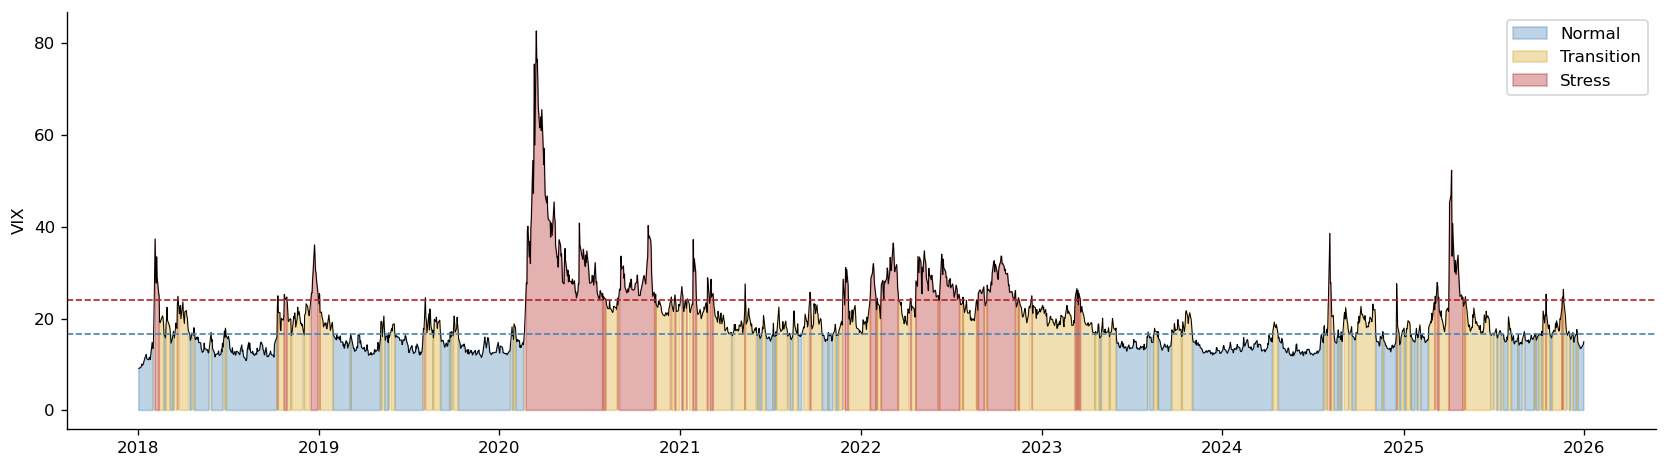

In [10]:
#| label: fig-vix
#| fig-cap: "VIX-Verlauf 2018–2025 mit Regimedefinition"

fig, ax = plt.subplots(figsize=(14, 4))

colors = {"Normal": "steelblue", 
          "Transition": "goldenrod", 
          "Stress": "firebrick"}

for label, color in colors.items():
    mask = regime == label
    ax.fill_between(vix.index, vix.values, where=mask.values,
                    alpha=0.35, color=color, label=label)

ax.plot(vix.index, vix.values, color="black", linewidth=0.6)
ax.axhline(q_low,  color="steelblue", linestyle="--", linewidth=1)
ax.axhline(q_high, color="firebrick", linestyle="--", linewidth=1)
ax.set_ylabel("VIX")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3.2 Charakterisierung der Renditeverteilungen
Die folgende Analyse verfolgt den methodischen Zweck, die Voraussetzungen für die Wahl der Korrelationsmaße und Inferenzmethoden in Kapitel 3.3 und 3.4 zu prüfen.

Tabelle 1 zeigt die deskriptiven Kennzahlen der über die Aktien gepoolten Log-Renditen, separat für Normal- und Stressregime. Bereits auf deskriptiver Ebene lassen sich systematische Unterschiede zwischen den Regimen erkennen.

In [11]:
def describe_regime(df, label):
    # Alle Aktien und Zeitpunkte zu einem Vektor
    x = df.stack().dropna()
    stats = pd.Series({
        "Regime": label,
        "Mean": x.mean(),
        "Median": x.median(),
        "Std": x.std(),
        "Min": x.min(),
        "Max": x.max(),
        "Skewness": x.skew(),
        "Excess Kurtosis": x.kurtosis()
    })
    return stats


desc_normal = describe_regime(ret_normal, "Normal")
desc_stress = describe_regime(ret_stress, "Stress")

desc_all = pd.DataFrame([desc_normal, desc_stress])

# Tabelle
desc_all.style.format("{:.4f}", subset=desc_all.select_dtypes("number")\
            .columns).hide(axis="index")\
            .set_caption("Deskriptive Statistik nach Regime")

Regime,Mean,Median,Std,Min,Max,Skewness,Excess Kurtosis
Normal,0.0018,0.0017,0.0193,-0.2395,0.4448,1.2507,33.1241
Stress,-0.0024,-0.0014,0.0396,-0.7736,0.3580,-1.3278,25.8334


Die Standardabweichung ist im Stressregime deutlich erhöht, was auf eine höhere Streuung der Einzelrenditen während dieser Marktphasen hinweist. Die mittleren täglichen Log-Renditen fallen im Stressregime niedriger sowie negativ aus, was auf stärkere Kursrückgänge in diesen Phasen hindeutet. Diese Verschiebung wird auch über die jeweiligen Extrema deutlich.

Besonders relevant für die weitere Analyse sind die Momente höherer Ordnung. Während die Verteilung in Normalphasen rechtsschief ist, zeigt sich eine negative Schiefe im Stressregime. Dies deutet auf eine asymmetrische Verteilung hin, wobei im Stressregime die linke Seite der Verteilung stärker ausgeprägt ist. Die Excess Kurtosis liegt in beiden Regimen deutlich über null, was auf Heavy Tails hinweist. 
Die höhere Excess Kurtosis im Normalregime (33,1 vs. 25,8) erklärt sich dadurch, dass Kurtosis Extremwerte relativ zur Standardabweichung gewichtet. Seltene Ausreißer fallen in einer sonst ruhigen Verteilung stärker ins Gewicht. 

Die erhöhte Standardabweichung wird rein deskriptiv interpretiert. Ein formaler Test, wie Levene oder Brown-Forsythe, ist wegen der zeitlichen Abhängigkeit der Volatilität ungeeignet.

@fig-qq zeigt Q-Q-Plots der gepoolten Log-Einzelrenditen gegen die theoretische Normalverteilung, separat für Normal- und Stressregime. In beiden Regimen ist eine S-förmige Krümmung erkennbar. Die empirischen Quantile weichen im linken Tail nach unten und im rechten Tail nach oben von der Referenzlinie ab. Dieses Muster ist konsistent mit der Excess Kurtosis in Tabelle 2.
Die Regime unterscheiden sich dabei in zwei Aspekten. Hinsichtlich des Ausmaßes der Abweichung reichen die Extremwerte im Stressregime bis −0,77 bzw. +0,36, gegenüber −0,24 bzw. +0,44 im Normalregime, was auf deutlich schwerere Tails im Stressregime hinweist. Hinsichtlich der Asymmetrie ist im Normalregime die Abweichung im rechten Tail ausgeprägter, konsistent mit der positiven Schiefe von 1,25. Im Stressregime kehrt sich dieses Bild um, da der linke Tail stärker abweicht, was mit der negativen Schiefe von −1,33 und dem asymmetrischen Verlaufsmuster von Marktkrisen übereinstimmt.

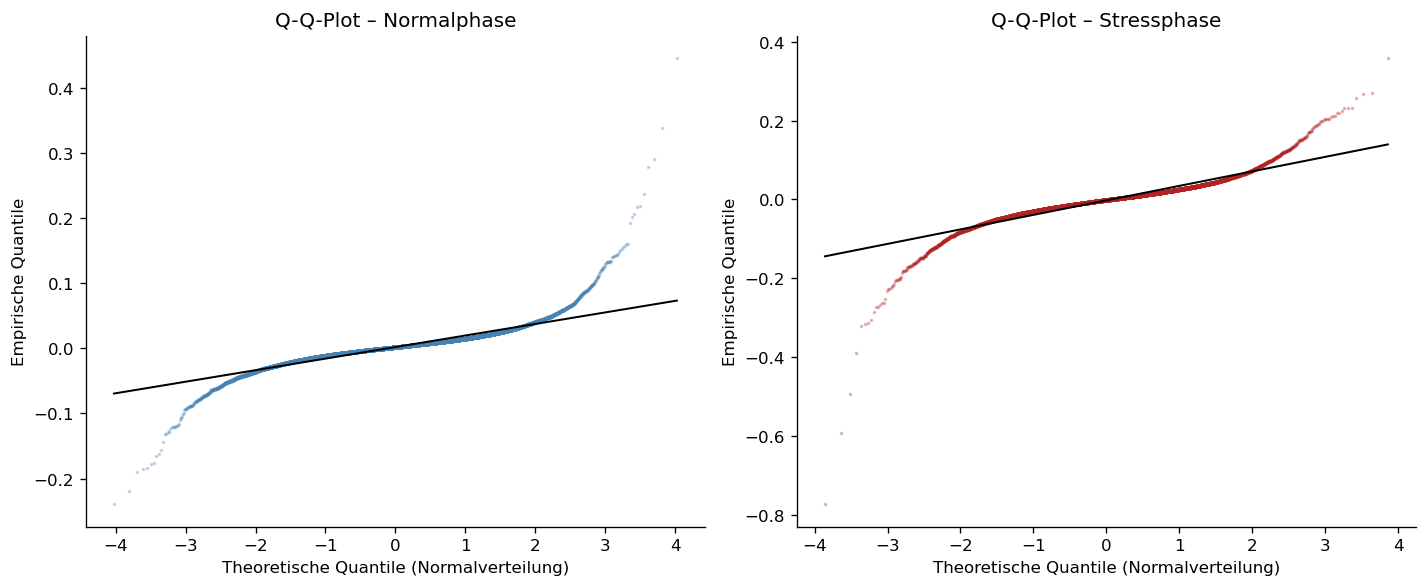

In [12]:
#| label: fig-qq
#| fig-cap: "Normalitätsdiagnostik; Q-Q-Plot der gepoolten Log-Renditen"
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, ret_df, label, farbe in zip(
        axes,
        [ret_normal, ret_stress],
        ["Normalphase", "Stressphase"],
        ["steelblue", "firebrick"]):

    daten = ret_df.values.flatten()
    stats.probplot(daten, dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=1.2, alpha=0.25, color=farbe)
    ax.get_lines()[1].set(color="black", linewidth=1.2)
    ax.set_title(f"Q-Q-Plot – {label}")
    ax.set_xlabel("Theoretische Quantile (Normalverteilung)")
    ax.set_ylabel("Empirische Quantile")

plt.tight_layout()
plt.show()

Ergänzend zu den visuellen Befunden eignet sich grundsätzlich der Jarque-Bera-Test, um die Normalität formal zu überprüfen. Dies gilt insbesondere bei Finanzrenditen, da er Abweichungen hinsichtlich Schiefe und Kurtosis erfasst. Die Hypothese $H_0^{JB}$: "Die Log-Renditen sind normalverteilt." wird in beiden Regimen abgelehnt (Normal: JB = 1.111.264, $p \approx 0$; Stress: JB = 339.446, $p \approx 0$ siehe Tabelle 2). Bei n > 20.000 gepoolten Beobachtungen ist dieses Ergebnis jedoch zu erwarten und hat wenig eigenständige Aussagekraft. Die praktische Bedeutsamkeit der Nicht-Normalität wird daher über die bereits interpretierten höheren Momente und die Plots beurteilt.

In [13]:
# Jarque-Bera-Test
jb_stress = stats.jarque_bera(ret_stress)
jb_normal = stats.jarque_bera(ret_normal)

# Tabelle
results = pd.DataFrame({
    "Phase": ["Stress", "Normal"],
    "JB-Statistik": [jb_stress.statistic, jb_normal.statistic],
    "p-Wert": [jb_stress.pvalue, jb_normal.pvalue] })

results.style.format({
            "JB-Statistik": "{:.1f}",
            "p-Wert": "{:.4f}",
            }).hide(axis="index")\
            .set_caption("Ergebnisse des Jarque-Bera-Tests")

Phase,JB-Statistik,p-Wert
Stress,339446.4,0.0000
Normal,1111264.1,0.0000


Die Normalverteilungsannahme ist entsprechend der Analyseergebnisse klar verletzt. Normalverteilungsbasierte Inferenzmethoden werden somit für die weitere Analyse ausgeschlossen.
Die Verteilungsanalyse zeigt, dass Heavy Tails in beiden Regimen deutlich vorliegen. Offen bleibt, ob Extremwerte im Stressregime systematisch häufiger auftreten und ob sektorale Unterschiede bestehen. @fig-boxplots zeigt Boxplots der täglichen Log-Renditen nach Sektor und Regime.

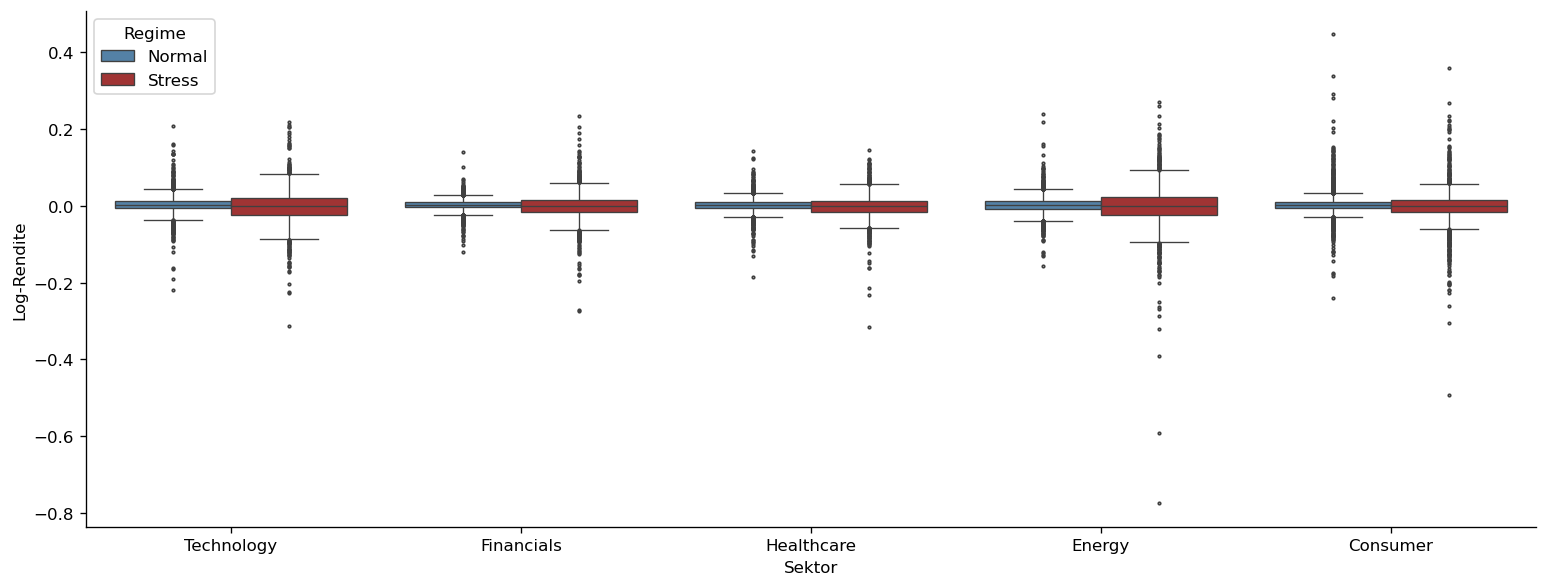

In [14]:
#| label: fig-boxplots
#| fig-cap: "Verteilung täglicher Log-Renditen nach Sektor und Regime"

# Für jeden Sektor: Verteilung der täglichen Renditen (gepoolt) je Regime
plot_data = []
for ticker in all_tickers:
    for day in ret_normal.index:
        plot_data.append({"Ticker": ticker, 
                          "Rendite": ret_normal.loc[day, ticker],
                          "Regime": "Normal", 
                          "Sektor": sector_map[ticker]})
    for day in ret_stress.index:
        plot_data.append({"Ticker": ticker, 
                          "Rendite": ret_stress.loc[day, ticker],
                          "Regime": "Stress",
                          "Sektor": sector_map[ticker]})

plot_df = pd.DataFrame(plot_data)

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=plot_df, x="Sektor", y="Rendite", hue="Regime",
            palette={"Normal": "steelblue", "Stress": "firebrick"},
            fliersize=1.5, linewidth=0.8, ax=ax)
ax.set_ylabel("Log-Rendite")
ax.legend(title="Regime")
plt.tight_layout()
plt.show()

Über alle Sektoren hinweg ist die Streuung im Stressregime deutlich größer als im Normalregime, erkennbar an breiteren Boxen und längeren Whiskers. Inhaltlich auffällig sind sektorale Unterschiede im Ausmaß dieser Aufweitung. Besonders starke Streuungszunahmen sind in Sektoren wie Energy und auch Financials zu verbuchen, was mit der besonderen Krisenexposition dieser Sektoren konsistent ist. Healthcare und Technology zeigen eine moderatere Aufweitung, was den defensiven Charakter dieser Sektoren widerspiegelt. Auch Consumer streut unter Stress moderat stärker, jedoch ist hier bereits in Normalphasen eine starke Varianz zu beobachten.

In beiden Regimen sind einige Datenpunkte außerhalb der Whiskers zu erkennen. Im Stressregime sind diese extremen Renditen häufiger und auch betragsmäßig größer. Der Anteil der Renditebeobachtungen, die den zweifachen Standardabweichungswert des Normalregimes überschreiten, beträgt 4,43% im Normal- und 19,37% im Stressregime. Dieser Anteil an Extremwerten und potenziellen Ausreißern kann die Pearson-Korrelation beeinflussen, wodurch den Robustheitscheck in Kapitel 3.4 motiviert.

In [15]:
threshold= 2 * ret_normal.values.std()
ext_n = (ret_normal.abs() > threshold).values.mean()
ext_s = (ret_stress.abs() > threshold).values.mean()

print(f"Anteil |r| > 2σ Normal: {ext_n:.2%}; Stress: {ext_s:.2%}; Faktor: {ext_s/ext_n:.1f}")

Anteil |r| > 2σ Normal: 4.43%; Stress: 19.37%; Faktor: 4.4


## 3.3 Analyse der Korrelationsstrukturen

Die Verteilungsanalyse liefert somit ein konsistentes Bild. Die Renditen sind nicht normalverteilt und extreme Renditen treten im Stressregime häufiger auf. Diese Befunde zusammen definieren den methodischen Rahmen für die Korrelationsanalyse. Der Pearson-Koeffizient wird als deskriptives Maß verwendet und die Inferenz erfolgt über verteilungsfreie Methoden. Zunächst erfolgt die Betrachtung der Korrelationsstruktur über die Heatmaps bzw. Differenzmatrix, um die paarweisen Korrelationen zu betrachten.

In [16]:
corr_normal = ret_normal.corr(method="pearson")
corr_stress = ret_stress.corr(method="pearson")
corr_diff = corr_stress - corr_normal

@fig-heatmaps a) zeigt die Pearson-Korrelationsmatrix für das Normalregime. Die Struktur ist erkennbar heterogen. Entlang der Diagonale sind Sektorblöcke erkennbar, in denen Aktien desselben Sektors untereinander höhere Korrelationen aufweisen als mit Aktien anderer Sektoren. Sektorübergreifende Paare zeigen deutlich niedrigere Werte. Die Sektorstruktur der Stichprobe ist damit im Normalregime klar ablesbar und spiegelt wider, dass gemeinsame Branchenfaktoren die Renditeentwicklung innerhalb eines Sektors stärker treiben als marktweite Faktoren.

@fig-heatmaps b) stellt die Differenzmatrix $$ \Delta \rho = \rho_{stress}-\rho_{normal} $$ dar. Alle Paare weisen einen positiven $\Delta\rho$-Wert auf, d.h. die Korrelation ist im Stressregime konsequent höher als im Normalregime. Der Anstieg ist breit gestreut und nicht auf einzelne Paare oder Sektoren konzentriert. Besonders ausgeprägte Anstiege zeigen sich innerhalb des Financials-Sektors (AMP, SPGI, COF, AFL, EG, WTW) sowie bei sektorübergreifenden Paaren mit Financial-Beteiligung. Die Differenzmatrix verdeutlicht, dass der Korrelationsanstieg ein systematisches Phänomen ist, das das gesamte Aktienuniversum der Stichprobe betrifft.

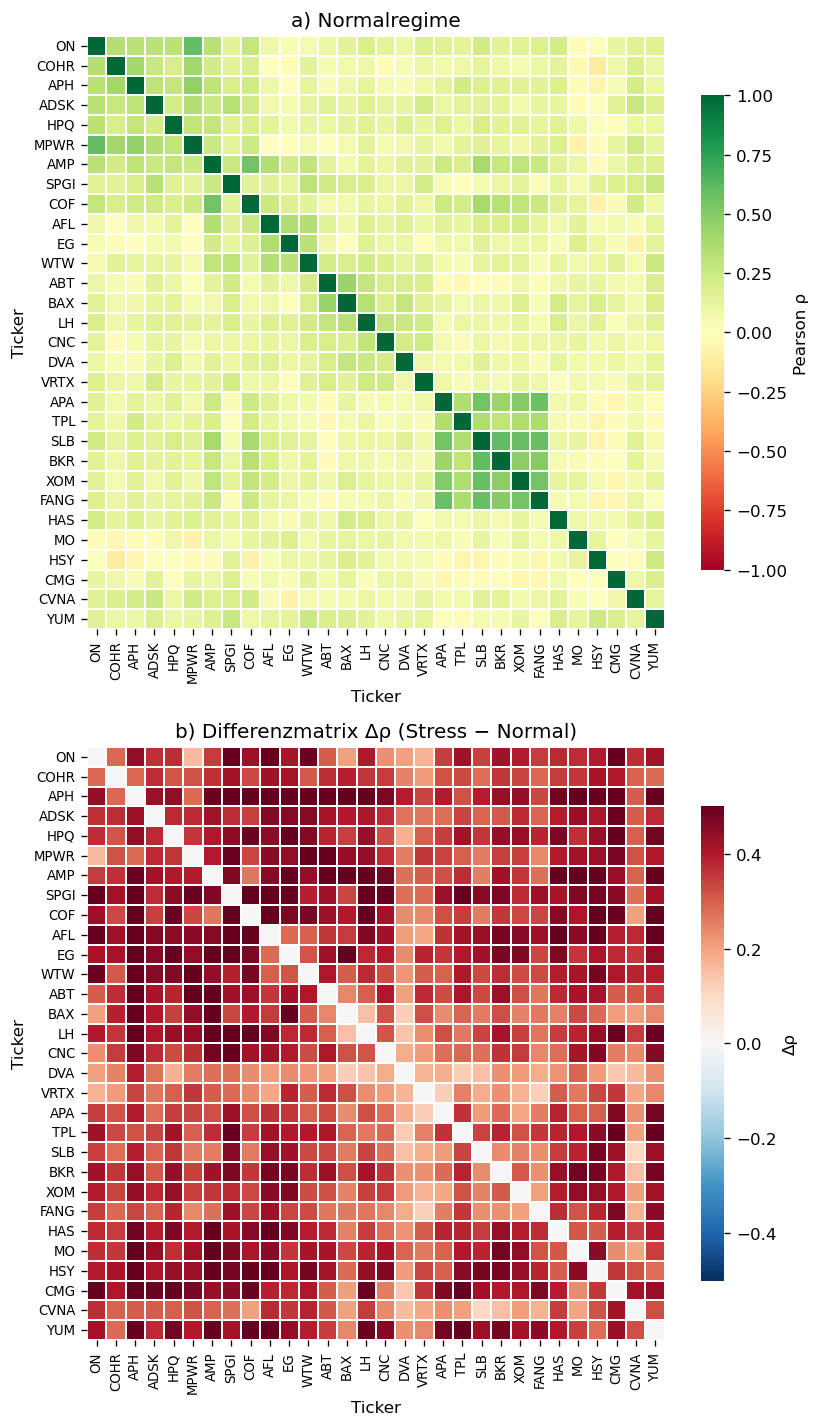

In [17]:
#| label: fig-heatmaps
#| fig-cap: "Heatmaps der paarweisen Pearson-Korrelation"

fig, axes = plt.subplots(2, 1, figsize=(7, 12))

# Normalregime
sns.heatmap(
    corr_normal,
    ax=axes[0],
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=True,
    linewidths=0.2,
    cbar_kws={"shrink": 0.8, "label": "Pearson ρ"}
)
axes[0].set_title("a) Normalregime")
axes[0].tick_params(labelsize=8)

# Differenzmatrix
sns.heatmap(
    corr_diff,
    ax=axes[1],
    cmap="RdBu_r",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    xticklabels=True,
    yticklabels=True,
    linewidths=0.2,
    cbar_kws={"shrink": 0.8, "label": "Δρ"}
)
axes[1].set_title("b) Differenzmatrix Δρ (Stress − Normal)")
axes[1].tick_params(labelsize=8)

plt.tight_layout()
plt.show()

{{< pagebreak >}}Die Heatmaps geben einen qualitativen Überblick der Veränderung der Korrelationsstruktur. Zur Prüfung der Forschungsfrage wird zusätzlich die durchschnittliche paarweise Korrelation zwischen den Regimen verglichen.

In [18]:
# durchschnittliche Korrelation
def avg_pairwise_corr(corr_matrix):
    n = corr_matrix.shape[0]
    upper = corr_matrix.values[np.triu_indices(n, k=1)]
    return upper.mean(), upper

mean_n, pairs_n = avg_pairwise_corr(corr_normal)
mean_s, pairs_s = avg_pairwise_corr(corr_stress)
# Output
print(f"Ø Paarweise Korrelation - Normal: {mean_n:.4f}")
print(f"Ø Paarweise Korrelation - Stress: {mean_s:.4f}")
print(f"Differenz:                        {mean_s - mean_n:+.4f}")

Ø Paarweise Korrelation - Normal: 0.1393
Ø Paarweise Korrelation - Stress: 0.5039
Differenz:                        +0.3646


Ausgegeben werden die durchschnittlichen paarweisen Pearson-Korrelationen, separat für Normal- und Stressregime. Der Mittelwert für das Stressregime ist gegenüber dem des Normalregimes deutlich höher. 
Die durchschnittliche paarweise Pearson-Korrelation beträgt 0,1393 im Normalregime und 0,5039 im Stressregime, was einer Differenz von Δ = 0,3646 entspricht. Die formale Inferenz zur Einschätzung, ob dieser Unterschied statistisch abgesichert ist, folgt in Kapitel 3.4. Eine genaue Auflistung der paarweisen Korrelationen der einzelnen Aktien ist in Anhang [A.2](#tabelle-a2-vollständige-paarweise-pearson-korrelationen) einzusehen.

Für die Interpretation ist der Volatility-Bias nach @forbes2002 zu berücksichtigen. Da die Renditevarianzen im Stressregime höher sind (Kapitel 3.2), überschätzt der beobachtete Pearson-Anstieg möglicherweise den tatsächlichen Anstieg der Abhängigkeitsstruktur. Wie viel des Anstiegs auf genuine Veränderungen der Abhängigkeitsstruktur und wie viel auf den Volatility Bias zurückzuführen ist, kann im Rahmen dieser Arbeit nicht abschließend getrennt werden.

Des Weiteren ist die Effektgröße inhaltlich einzuordnen. Nach @cohen1988 gelten Korrelationen von etwa 0,10, 0,30 und 0,50 als Orientierung für kleine, mittlere und große Effekte. Die beobachtete Differenz von $\Delta \rho = 0,3646$ stellt damit deskriptiv einen deutlichen Anstieg der durchschnittlichen Korrelation dar. Cohens Schwellenwerte beziehen sich auf die Höhe einer Korrelation und sind daher nicht unmittelbar auf Korrelationsdifferenzen übertragbar.

Der Anstieg der Durchschnittskorrelation stützt $H_1$ auf deskriptiver Ebene. Anschließend wird untersucht, ob die Veränderung sektorübergreifend gleichmäßig auftritt und welche Bedeutung dies für die Diversifikation hat.

In [19]:
def sector_corr_summary(corr_matrix, sector_map):
    """Gibt Ø-Korrelation innerhalb und zwischen Sektoren zurück."""
    rows = []
    tickers = list(corr_matrix.columns)
    for i, ti in enumerate(tickers):
        for j, tj in enumerate(tickers):
            if j <= i:
                continue
            si, sj = sector_map[ti], sector_map[tj]
            rows.append({
                "Sektor_i": si,
                "Sektor_j": sj,
                "Typ": "Innerhalb" if si == sj else "Zwischen",
                "Korrelation": corr_matrix.loc[ti, tj]
            })
    return pd.DataFrame(rows)

df_sec_n = sector_corr_summary(corr_normal, sector_map)
df_sec_s = sector_corr_summary(corr_stress, sector_map)
df_sec_n["Regime"] = "Normal"
df_sec_s["Regime"] = "Stress"
df_sec = pd.concat([df_sec_n, df_sec_s], ignore_index=True)

# Tabelle
summary_table = df_sec.groupby(["Regime", "Typ"])["Korrelation"]\
    .agg(["mean","std","count"])
summary_table.columns = ["Mittelwert", "Std.-Abw.", "Paare"]

summary_table.style.format({
                "Mittelwert": "{:.4f}",
                "Std.-Abw.": "{:.4f}",
                "Paare": "{:.0f}", 
                })\
                .set_caption("Vergleich Within- und Between-Korrelation")


Tabelle 3 zeigt die durchschnittliche paarweise Korrelation aufgeteilt nach Within-Sektor-Paaren (beide Aktien aus demselben Sektor) und Between-Sektor-Paaren (Aktien aus verschiedenen Sektoren), jeweils für Normal- und Stressregime.
Im Normalregime ist der Unterschied zwischen Within- und Between-Korrelation deutlich. Within-Paare weisen eine durchschnittliche Korrelation von 0,2848 auf, Between-Paare von 0,1090. Diese Spreizung spiegelt die inhaltliche Erwartung wider, dass Aktien desselben Sektors durch gemeinsame Branchenfaktoren stärker korreliert sind.
Im Stressregime steigen beide Typen an, jedoch verringert sich die Spreizung zwischen ihnen. Die Within-Korrelation steigt auf 0,6121, die Between-Korrelation auf 0,4814. Der stärkere relative Anstieg der Between-Korrelation hat eine direkte praktische Implikation. Eine Portfoliostrategie, die auf Sektordiversifikation setzt, verliert im Stressregime an Wirksamkeit, weil die sektorübergreifenden Korrelationen ansteigen. 

Tabelle 4 und @fig-within verdeutlichen ergänzend die Veränderung der Within-Korrelation, aufgeschlüsselt nach den einzelnen Sektoren. Financials zeigt den stärksten relativen Anstieg, Energy den moderatesten, was sich wiederum mit der unterschiedlichen Krisenexposition der Sektoren erklären ließe. Da diese sektorale Aufschlüsselung auf lediglich sechs Aktien je Sektor beruht, ist die Rangfolge der Sektoren mit größerer Schätzunsicherheit behaftet als die aggregierte Gesamtkorrelation und wird daher hier rein deskriptiv interpretiert.

In [20]:
within = df_sec[df_sec["Typ"] == "Innerhalb"].copy()

pivot = within.groupby(["Sektor_i", "Regime"])["Korrelation"]\
    .mean().unstack("Regime")
pivot.columns.name = None

pivot.style.format({
                "Normal": "{:.4f}",
                "Stress": "{:.4f}",
                })\
    .set_caption("Durchschnittliche sektorale Pearson-Korrelation")

,Normal,Stress
Sektor_i,,
Consumer,0.1031,0.4437
Energy,0.4752,0.7529
Financials,0.2670,0.6943
Healthcare,0.2406,0.4869
Technology,0.3379,0.6829


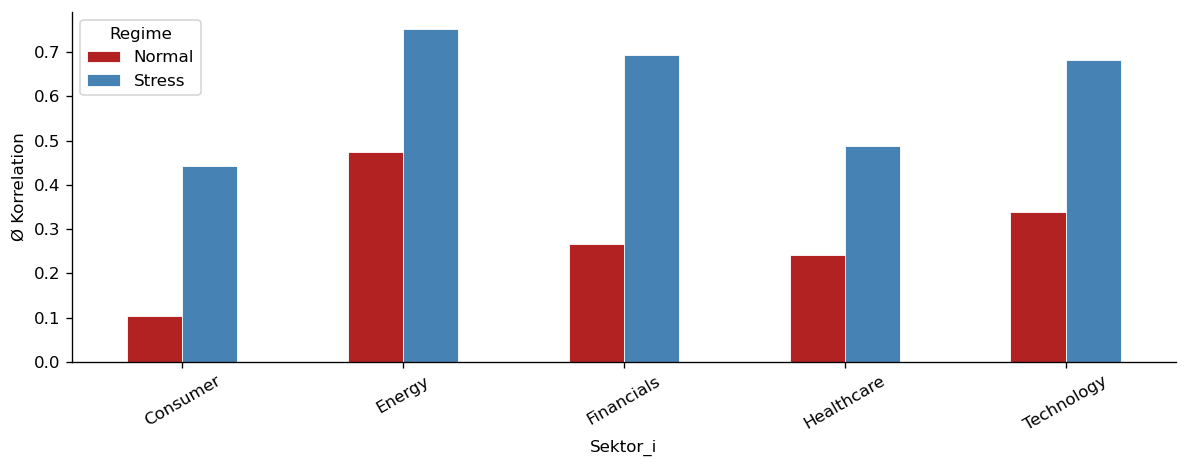

In [21]:
#| label: fig-within
#| fig-cap: "Sektorale durchschnittliche Korrelation (innerhalb des Sektors) je Regime"

ax = pivot.plot(kind="bar", figsize=(10, 4), color=["firebrick", "steelblue"],
                edgecolor="white", linewidth=0.5)
ax.set_ylabel("Ø Korrelation")
ax.set_xticklabels(pivot.index, rotation=30)
ax.legend(title="Regime")
plt.tight_layout()
plt.show()

## 3.4 Robustheit und Inferenz
Als Robustheitscheck wird die Pearson-Korrelation mit der Spearman-Rangkorrelation verglichen. Spearman ist als rangbasiertes Maß robust gegenüber Ausreißern. Da statt der absoluten Werte nur die Rangordnung der Beobachtungen eingehen, haben Extremrenditen keinen überproportionalen Einfluss. Dies ist relevant, weil im Stressregime deutlich mehr Extremrenditen auftreten (Kapitel 3.2) und diese die Pearson-Schätzung potenziell verzerren könnten.

@fig-pearsonspearman zeigt für alle paarweisen Korrelationen den Scatter-Plot von Pearson $\rho$ gegen Spearman $\rho$, separat für Normal- und Stressregime. Eine hohe Übereinstimmung mit der 45°-Linie zeigt an, dass beide Maße zu ähnlichen Ergebnissen kommen. Beide Scatterplots zeigen, dass die einzelnen Datenpunkte deutlich entlang der Linie verteilt liegen, wobei auch hier erkennbar ist, dass diese im Stress stärker nach rechts verschoben sind. Diese grafische Betrachtung legt nahe, dass Pearson und Spearman die paarweisen Abhängigkeiten konsistent einschätzen. Die durchschnittliche Spearman-Korrelation beträgt 0,1834 im Normal- und 0,4785 im Stressregime; der Anstieg von Δ = 0,2951 ist mit dem Pearson-Befund vergleichbar.
Der Robustheitscheck bestätigt damit, dass das Hauptergebnis aus Kapitel 3.3 nicht durch Ausreißer getrieben ist. Pearson- und Spearman-Korrelation liefern konsistente Befunde, was die Validität der Korrelationsanalyse stärkt.

In [22]:
corr_sp_normal = ret_normal.corr(method="spearman")
corr_sp_stress = ret_stress.corr(method="spearman")
 
_, sp_pairs_n = avg_pairwise_corr(corr_sp_normal)
_, sp_pairs_s = avg_pairwise_corr(corr_sp_stress)

# Output
print(f"Spearman Ø - Normal: {sp_pairs_n.mean():.4f}")
print(f"Spearman Ø - Stress: {sp_pairs_s.mean():.4f}")
print(f"Pearson  Ø - Normal: {pairs_n.mean():.4f}")
print(f"Pearson  Ø - Stress: {pairs_s.mean():.4f}")

Spearman Ø - Normal: 0.1834
Spearman Ø - Stress: 0.4785
Pearson  Ø - Normal: 0.1393
Pearson  Ø - Stress: 0.5039


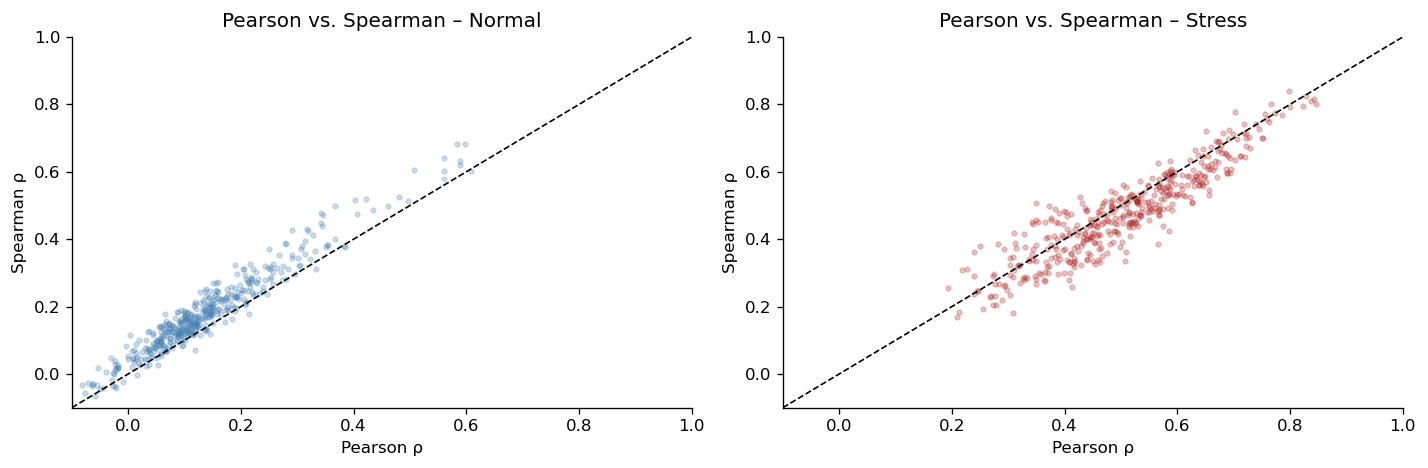

In [23]:
#| label: fig-pearsonspearman
#| fig-cap: "Vergleich von Pearson- und Spearman-Korrelation"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
 
for ax, (px, sp, label, color) in zip(axes, [
        (pairs_n, sp_pairs_n, "Normal", "steelblue"),
        (pairs_s, sp_pairs_s, "Stress", "firebrick")]):
 
    ax.scatter(px, sp, alpha=0.25, s=8, color=color)
    lims = [-0.1, 1.0]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Pearson ρ")
    ax.set_ylabel("Spearman ρ")
    ax.set_title(f"Pearson vs. Spearman – {label}")
 
plt.tight_layout()
plt.show()

Zur inferenzstatistischen Absicherung werden Block-Bootstrap-Konfidenzintervalle verwendet. Klassische normalverteilungsbasierte Tests werden aufgrund der beobachteten Nicht-Normalität nicht verwendet. Nicht-parametrische Tests wie Mann-Whitney setzen unabhängige Beobachtungen voraus, was für die aus denselben Renditedaten berechneten paarweisen Korrelationskoeffizienten nicht gegeben ist. Der Bootstrap operiert stattdessen auf Ebene der Handelstage. In jeder Replikation werden ganze Tagesvektoren mit allen 30 Aktienrenditen gemeinsam gezogen und die Korrelationsmatrix bzw. die durchschnittliche Korrelation als Testgröße berechnet.
 
Finanzzeitreihen weisen zeitliche Abhängigkeiten auf, insbesondere durch Volatility Clustering. Aus diesem Grund wird der Block-Bootstrap nach @kuensch1989 mit 2.000 Replikationen verwendet. Statt Einzeltagen werden Blöcke aufeinanderfolgender Tage gezogen, was die zeitliche Abhängigkeitsstruktur der Daten berücksichtigt. Die Blockgröße beträgt 20 Handelstage, entsprechend etwa einem Handelsmonat. Für den Vergleich der beiden Regime wird in jeder Bootstrap-Replikation die Differenz der durchschnittlichen Korrelationen berechnet. 

In [24]:
%run -i bootstrap.py

Bootstrap 95%-KI der Differenz: 0.3573 [0.2512, 0.4447]


Das 95%-Konfidenzintervall dieser Differenz enthält den Wert null nicht, sodass der Unterschied auf dem 5%-Niveau als statistisch signifikant gilt. Der Bootstrap-Mittelwert der Differenz liegt mit 0,357 zudem nahe an der Differenz der Punktschätzer aus Kapitel 3.3 (0,5039 − 0,1393 = 0,3646), was einen Plausibilitätscheck der Implementierung darstellt. Eine Sensitivitätsanalyse mit alternativen Blockgrößen von 10 und 40 Tagen (siehe Anhang [A.3](#tabelle-a3-sensitivitätsanalyse-der-blockgrößen)) bestätigt die Robustheit der Ergebnisse gegenüber dieser Wahl.

{{< pagebreak >}}

# 4 Zusammenfassung

## 4.1 Hauptergebnisse
Die vorliegende Arbeit untersuchte, ob sich die durchschnittliche paarweise Korrelation von S&P-500-Aktien zwischen Phasen niedriger und hoher Marktanspannung systematisch unterscheidet. Die Analyse prüfte $H_1$: "Die durchschnittliche paarweise Korrelation ist im Stressregime höher als im Normalregime" auf Basis einer stratifizierten Zufallsstichprobe von 30 S&P-500-Aktien.

Die deskriptiven Ergebnisse zeigen einen deutlichen Anstieg der durchschnittlichen Pearson-Korrelation vom Normalregime ($\rho = 0,1393$) zum Stressregime ($\rho = 0,5039$), entsprechend einer Differenz von $\Delta = 0,3646$. Die Differenzmatrix verdeutlicht, dass jedes einzelne der gezogenen Aktienpaare im Stressregime höhere Korrelationen aufweist. Der Anstieg ist somit kein Einzelfall, sondern ein systematisches Phänomen über die gesamte Stichprobe. Zudem ist die Verteilung der Korrelationen im Stressregime homogener, was auf ein stärker gleichgerichtetes Verhalten der Aktien hindeutet.
Da die Log-Renditen in beiden Regimen nicht normalverteilt sind (Excess Kurtosis: 33,12 bzw. 25,83), wurden keine parametrischen Verfahren eingesetzt. Der Vergleich mit Spearman-Korrelationen bestätigt, dass der Befund nicht ausschließlich auf lineare Zusammenhänge oder einzelne Ausreißer zurückzuführen ist.

Die inferenzstatistische Analyse mittels Bootstrap-Konfidenzintervall der Differenz zeigt, dass das 95%-Konfidenzintervall den Wert null nicht enthält. Damit ist der beobachtete Korrelationsanstieg auf dem 5%-Niveau statistisch signifikant. Insgesamt liefern sowohl die deskriptiven als auch die inferenzstatistischen Ergebnisse deutliche Evidenz zugunsten von $H_1$.

## 4.2 Limitationen
Der beobachtete Pearson-Anstieg ist als obere Schranke zu interpretieren. Da die Renditevarianzen im Stressregime höher sind, kann nach @forbes2002 ein Volatility Bias in Pearson-Korrelationen entstehen. Wie viel des Anstiegs auf genuine Abhängigkeitsveränderungen zurückzuführen ist, kann ohne bias-korrigierten Schätzer nicht getrennt werden. Darüber hinaus erfasst Pearson ausschließlich lineare Abhängigkeiten, die Regimedefinition ist statisch, und die Ergebnisse sind auf US-Großunternehmen im S&P 500 begrenzt. Eine Generalisierung ist somit nicht zulässig.


{{< pagebreak >}}

# Referenzen
::: {#refs}
:::

{{< pagebreak >}}

# Anhang
## Tabelle A.1: Vollständige Stichprobenübersicht

In [25]:
constituents = pd.read_csv("constituents.csv")

overview = (
    pd.DataFrame(
        [(t, sector_map[t]) for t in all_tickers],
        columns=["Ticker", "Sektor"]
    )
    .merge(
        constituents[["Symbol", "Security"]],
        left_on="Ticker",
        right_on="Symbol",
        how="left"
    )
    .rename(columns={"Security": "Unternehmen"})
    [["Ticker", "Unternehmen", "Sektor"]]
    .sort_values(["Sektor", "Ticker"])
    .reset_index(drop=True)
)
overview.index += 1

overview

,Ticker,Unternehmen,Sektor
1,CMG,Chipotle Mexican Grill,Consumer
2,CVNA,Carvana,Consumer
3,HAS,Hasbro,Consumer
4,HSY,Hershey Company (The),Consumer
5,MO,Altria,Consumer
6,YUM,Yum! Brands,Consumer
7,APA,APA Corporation,Energy
8,BKR,Baker Hughes,Energy
9,FANG,Diamondback Energy,Energy
10,SLB,Schlumberger,Energy


{{< pagebreak >}}

## Tabelle A.2: Vollständige paarweise Pearson-Korrelationen

In [26]:
n = corr_normal.shape[0]
iu = np.triu_indices(n, k=1)
tickers = corr_normal.columns

df_corr_long = pd.DataFrame({
    "Ticker 1": [tickers[i] for i in iu[0]],
    "Ticker 2": [tickers[j] for j in iu[1]],
    "Pearson Normal": corr_normal.values[iu].round(4),
    "Pearson Stress": corr_stress.values[iu].round(4),
})
df_corr_long["Delta"] = (
    df_corr_long["Pearson Stress"] - df_corr_long["Pearson Normal"]
).round(4)
df_corr_long = df_corr_long.sort_values("Delta", ascending=False).reset_index(drop=True)

pd.set_option('display.max_rows', None)
df_corr_long

,Ticker 1,Ticker 2,Pearson Normal,Pearson Stress,Delta
0,APH,EG,0.0059,0.6541,0.6482
1,APH,CMG,0.0438,0.6284,0.5846
2,APH,AFL,0.0859,0.6692,0.5833
3,AFL,HSY,0.0432,0.6252,0.5820
4,AMP,HSY,-0.0294,0.5490,0.5784
5,APH,YUM,0.1056,0.6724,0.5668
6,COF,YUM,0.0913,0.6579,0.5666
7,ON,AFL,0.0836,0.6475,0.5639
8,APH,HSY,-0.0634,0.4986,0.5620
9,SPGI,TPL,0.0158,0.5741,0.5583


{{< pagebreak >}}

## Tabelle A.3: Sensitivitätsanalyse der Blockgrößen

In [27]:
block_sizes_new = [10, 40]  # nur diese neu berechnen

sensitivity_results = [
    {
        "Blockgröße": 20,  # wird von oben übernommen
        "Differenz Mean": f"{boot_diff.mean():.4f}",
        "Differenz CI": f"[{ci_diff[0]:.4f}, {ci_diff[1]:.4f}]",
    }
]

for bs in block_sizes_new:
    boot_diff_bs = block_bootstrap_diff(
        ret_normal,
        ret_stress,
        block_size=bs,
        n_boot=2000
    )

    ci_diff_bs = np.percentile(boot_diff_bs, [2.5, 97.5])

    sensitivity_results.append({
        "Blockgröße": bs,
        "Differenz Mean": f"{boot_diff_bs.mean():.4f}",
        "Differenz CI": f"[{ci_diff_bs[0]:.4f}, {ci_diff_bs[1]:.4f}]",
    })

df_sensitivity = (
    pd.DataFrame(sensitivity_results)
    .sort_values("Blockgröße")
    .reset_index(drop=True)
)

df_sensitivity

,Blockgröße,Differenz Mean,Differenz CI
0,10,0.3589,"[0.2756, 0.4372]"
1,20,0.3573,"[0.2512, 0.4447]"
2,40,0.3482,"[0.2374, 0.4426]"


In [28]:
# set EXPORT to True and run this cell for export
EXPORT = False
if EXPORT:
  !jupyter nbconvert report_notebook.ipynb \
        --to html \
        --no-input > /dev/null 2>&1